# Chapter 24: Moral Hazard and Principal-Agent Incentives

This notebook reruns four worked examples from the chapter: a revenue split between two hidden efforts, the rent created by limited liability, a deductible that restores care, and a base plus bonus contract. Every example is hypothetical, as in the book; a few extra input values are added for comparison.

## Setup

The functions below are the calculations behind every number in this notebook. Run this cell first.

In [1]:
import math
from types import SimpleNamespace

import numpy as np
import matplotlib
import matplotlib.pyplot as plt



PALETTE = {
    "ink": "#172a3b",
    "teal": "#136f75",
    "gold": "#8f5d0f",
    "navy": "#334c72",
    "terracotta": "#a24a33",
    "olive": "#5d6a37",
    "grey": "#6b757b",
    "light": "#c9d3d6",
}


CYCLE = ["teal", "navy", "gold", "terracotta", "olive", "grey"]


LABEL_SIZE = 10.5


HOUSE_RC = {
    "font.size": 11.5,
    "axes.titlesize": 12,
    "axes.labelsize": 11.5,
    "xtick.labelsize": 10.5,
    "ytick.labelsize": 10.5,
    "legend.fontsize": 10.5,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#6b757b",
    "axes.labelcolor": "#172a3b",
    "xtick.color": "#172a3b",
    "ytick.color": "#172a3b",
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "svg.fonttype": "path",
}


def color(name_or_index):
    """Palette colour by name ('teal') or by position in the series cycle (0, 1, ...)."""
    if isinstance(name_or_index, int):
        return PALETTE[CYCLE[name_or_index % len(CYCLE)]]
    return PALETTE.get(name_or_index, name_or_index)


def tex_safe(text):
    """Escape dollar signs so Matplotlib does not read '$...$' as mathematics."""
    return str(text).replace("\\$", "$").replace("$", r"\$")


def new_figure(ncols=1, width=None, height=4.3):
    """Notebook twin of readerkit.new_figure: one panel 6.6 x 4.3 in, two panels 10.4 x 4.3 in."""
    import matplotlib.pyplot as plt

    if width is None:
        width = 6.6 if ncols == 1 else 10.4
    fig, axes = plt.subplots(1, ncols, figsize=(width, height), layout="constrained")
    for ax in (axes if ncols > 1 else [axes]):
        ax.grid(alpha=0.18)
    return fig, axes


def label(ax, x, y, text, col="ink", dx=6, dy=6, ha="left", va="bottom", box=True, size=LABEL_SIZE):
    """Direct label at data point (x, y) offset by (dx, dy) points, with a white box by default."""
    kw = {}
    if box:
        kw["bbox"] = {"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9}
    return ax.annotate(tex_safe(text), (x, y), xytext=(dx, dy), textcoords="offset points", ha=ha, va=va,
                       color=color(col), fontsize=size, **kw)


def mark(ax, x, y, text=None, col="ink", size=42, dx=6, dy=6, ha="left", va="bottom", zorder=5):
    """Filled point with an optional direct label."""
    ax.scatter([x], [y], s=size, color=color(col), zorder=zorder)
    if text:
        label(ax, x, y, text, col=col, dx=dx, dy=dy, ha=ha, va=va)


def hline(ax, y, text=None, col="grey", style="dashed", x_frac=0.02, va="bottom", lw=1.4):
    """Horizontal reference line with an optional label at the left edge."""
    ax.axhline(y, color=color(col), linestyle=style, linewidth=lw)
    if text:
        ax.annotate(tex_safe(text), (x_frac, y), xycoords=("axes fraction", "data"), xytext=(0, 4 if va == "bottom" else -4),
                    textcoords="offset points", ha="left", va=va, color=color(col), fontsize=LABEL_SIZE,
                    bbox={"boxstyle": "round,pad=0.18", "fc": "white", "ec": "none", "alpha": 0.9})


def bar_compare(ax, names, values, colors=None, value_labels=None, ylabel="Value", xlabel="Item", fmt=None,
                zero_line=True):
    """Labelled vertical bars, one per name; each bar carries its value label.

    ``value_labels`` gives the text over each bar (else ``fmt(v)`` or '{:,.2f}').
    Negative bars are allowed; labels go below them.
    """
    values = [float(v) for v in values]
    colors = colors or [color(i) for i in range(len(values))]
    xs = np.arange(len(values))
    ax.bar(xs, values, color=[color(c) for c in colors], width=0.6)
    ax.set_xticks(xs, names)
    lo, hi = min(0.0, min(values)), max(0.0, max(values))
    span = (hi - lo) or 1.0
    ax.set_ylim(lo - (0.14 * span if lo < 0 else 0), hi + 0.16 * span)
    for x, v, i in zip(xs, values, range(len(values))):
        text = value_labels[i] if value_labels else (fmt(v) if fmt else f"{v:,.2f}")
        ax.annotate(text, (x, v), xytext=(0, 4 if v >= 0 else -4), textcoords="offset points", ha="center",
                    va="bottom" if v >= 0 else "top", fontsize=LABEL_SIZE, color=PALETTE["ink"])
    if zero_line and lo < 0:
        ax.axhline(0, color=PALETTE["grey"], linewidth=1)
    ax.set_ylabel(ylabel)
    ax.set_xlabel(xlabel)
    return ax


def num(value, digits=2, comma=True):
    """Fixed-decimal string with optional thousands separators: num(1444.444) -> '1,444.44'.

    Negative zero prints as '0'. Raises ValueError on NaN or infinity, because an
    undefined value must be named in words (see ``undefined``).
    """
    value = float(value)
    if not math.isfinite(value):
        raise ValueError("non-finite value; name it with undefined(reason)")
    text = f"{value:,.{digits}f}" if comma else f"{value:.{digits}f}"
    if text.startswith("-") and float(text.replace(",", "")) == 0:
        text = text[1:]
    return text


def money(value, digits=2, comma=True):
    """Dollar amount: money(1444.444) -> '$1,444.44'; money(-480, 0) -> '-$480'."""
    text = num(value, digits, comma)
    return f"-${text[1:]}" if text.startswith("-") else f"${text}"


def double_moral_hazard(alpha, a=40.0, b=40.0, c=10.0):
    """double-moral-hazard (EP-120): revenue a e + b m, costs c e^2 and c m^2, developer share alpha.

    Each party sets its marginal share equal to marginal cost: alpha a = 2 c e and (1 - alpha) b = 2 c m.
    Book (ch024): alpha 0.75 gives e = 1.5, m = 0.5, revenue 80, cost 25, surplus 55; alpha 0.5 gives 60;
    the efficient levels e = m = 2 give surplus 80.
    """
    e = alpha * a / (2 * c)
    m = (1 - alpha) * b / (2 * c)
    revenue = a * e + b * m
    cost = c * e * e + c * m * m
    e_eff, m_eff = a / (2 * c), b / (2 * c)
    efficient = a * e_eff + b * m_eff - c * (e_eff ** 2 + m_eff ** 2)
    return {"e": e, "m": m, "revenue": revenue, "cost": cost, "surplus": revenue - cost,
            "e_eff": e_eff, "m_eff": m_eff, "efficient_surplus": efficient}


def limited_liability_bonus(c, p0, p1, value, limited=True):
    """limited-liability-information-rents (EP-138): cheapest contract inducing high effort.

    Limited liability (w_L = 0): w_H = c / (p1 - p0), rent = p1 w_H - c = c p0 / (p1 - p0).
    Unlimited: keep the spread c / (p1 - p0) and set w_L so the expected wage equals c (rent 0).
    Book (ch024): c 12, p 0.30 and 0.70, value 100 gives w_H 30, expected wage 21, rent 9, company 49;
    unlimited gives w_H 21, w_L -9, expected wage 12, company 58. Ties go to high effort, as in the book.
    """
    spread = c / (p1 - p0)
    if limited:
        w_l, w_h = 0.0, spread
    else:
        w_l = c - p1 * spread
        w_h = w_l + spread
    wage = p1 * w_h + (1 - p1) * w_l if limited else float(c)
    return {"spread": spread, "w_H": w_h, "w_L": w_l, "expected_wage": wage, "rent": wage - c,
            "company": p1 * value - wage}


def deductible_care(D, care_cost, p0, p1, loss=None):
    """moral-hazard: a risk-neutral insured with deductible D takes care when (p0 - p1) D > care_cost.

    Resource cost is care_cost + p1 loss with care and p0 loss without. ``loss`` defaults to D.
    Book (ch024): care 80, loss 2,000, p 0.10 and 0.02; D 2,000 (no insurance) saves 160, cost 120;
    D 0 (full insurance) no care, cost 200; D 1,500 saves 120, care restored. Threshold D = 1,000 is a tie.
    """
    loss = D if loss is None else loss
    saving = (p0 - p1) * D
    if abs(saving - care_cost) < 1e-9:
        care = None
    else:
        care = saving > care_cost
    cost_care = care_cost + p1 * loss
    cost_none = p0 * loss
    return {"saving": saving, "care": care, "threshold": care_cost / (p0 - p1), "cost_with_care": cost_care,
            "cost_without_care": cost_none, "resource_cost": cost_care if care else cost_none}


def binary_effort_contract(base, bonus, p0, p1, cost, outside, value=None):
    """principal-agent: base plus success bonus, low effort free, high effort costs ``cost``.

    Agent nets base + p0 bonus (low) or base + p1 bonus - cost (high); an exact tie goes to high effort
    (the chapter's convention). The agent accepts when the chosen net is at least ``outside``.
    Book (ch024): base 15,000, bonus 22,000, p 0.20 and 0.50, cost 6,000, outside 20,000, sale 100,000:
    low 19,400, high pay 26,000 and net 20,000, principal profit 24,000.
    """
    low = base + p0 * bonus
    high_pay = base + p1 * bonus
    high = high_pay - cost
    tie = abs(high - low) < 1e-9
    effort = "high" if high >= low - 1e-9 else "low"
    net = high if effort == "high" else low
    accepted = net >= outside - 1e-9
    p = p1 if effort == "high" else p0
    pay = high_pay if effort == "high" else low
    out = {"low_net": low, "high_pay": high_pay, "high_net": high, "tie": tie, "effort": effort,
           "agent_net": net, "accepted": accepted, "expected_pay": pay}
    if value is not None:
        out["profit"] = (p * value - pay) if accepted else 0.0
    return out


plt.rcParams.update(HOUSE_RC)


information = SimpleNamespace(double_moral_hazard=double_moral_hazard, limited_liability_bonus=limited_liability_bonus, deductible_care=deductible_care, binary_effort_contract=binary_effort_contract)


# The book's printed values for this chapter (inputs of the worked examples).
BV = {'double-moral-hazard': {'a': 40,
                         'b': 40,
                         'c': 10,
                         'e_eff': 2,
                         'm_eff': 2,
                         'revenue_eff': 160,
                         'cost_eff': 80,
                         'surplus_eff': 80,
                         'alpha_half': 0.5,
                         'e_half': 1,
                         'm_half': 1,
                         'revenue_half': 80,
                         'cost_half': 20,
                         'surplus_half': 60,
                         'alpha': 0.75,
                         'e': 1.5,
                         'm': 0.5,
                         'revenue': 80,
                         'cost': 25,
                         'surplus': 55},
 'limited-liability-information-rents': {'cost': 12,
                                         'p0': 0.3,
                                         'p1': 0.7,
                                         'value': 100,
                                         'w_H': 30,
                                         'expected_wage': 21,
                                         'rent': 9,
                                         'company': 49,
                                         'w_H_unlimited': 21,
                                         'w_L_unlimited': -9,
                                         'expected_wage_unlimited': 12,
                                         'company_unlimited': 58},
 'moral-hazard': {'care_cost': 80,
                  'loss': 2000,
                  'p0': 0.1,
                  'p1': 0.02,
                  'saving_uninsured': 160,
                  'cost_with_care': 120,
                  'cost_without_care': 200,
                  'deductible': 1500,
                  'saving_deductible': 120},
 'principal-agent': {'outside': 20000,
                     'cost': 6000,
                     'p0': 0.2,
                     'p1': 0.5,
                     'sale': 100000,
                     'flat': 20000,
                     'flat_profit': 0,
                     'base': 15000,
                     'bonus': 22000,
                     'low_pay': 19400,
                     'high_pay': 26000,
                     'high_net': 20000,
                     'profit': 24000},
 'constructed': {'double-moral-hazard': {'alphas': [0.5, 0.6, 0.75, 0.9]},
                 'limited-liability-information-rents': {'costs': [8, 12, 16]},
                 'moral-hazard': {'deductibles': [0, 500, 1500, 2000], 'threshold_tie': 1000},
                 'principal-agent': {'bonuses': [0, 15000, 20000, 22000], 'bases': [15000, 20000]}}}


def sharing_picture(alpha=0.75):
    r = information.double_moral_hazard(alpha, 40, 40, 10)
    e, m = r["e"], r["m"]
    fig, (ax, bx) = new_figure(ncols=2)
    grid = np.linspace(0, 1, 201)
    ax.plot(grid, [information.double_moral_hazard(a)["surplus"] for a in grid], color=PALETTE["teal"],
            linewidth=2.2)
    hline(ax, r["efficient_surplus"], f"efficient surplus {num(r['efficient_surplus'], 0)}", col="gold",
          x_frac=0.3, va="top")
    mark(ax, alpha, r["surplus"], f"alpha = {num(alpha)}: {num(r['surplus'])}", col="terracotta",
         dx=-8 if alpha > 0.6 else 8, dy=-14, ha="right" if alpha > 0.6 else "left", va="top")
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 90)
    ax.set_xlabel("Developer share alpha")
    ax.set_ylabel("Joint surplus")
    bar_compare(bx, ["Developer e", "Distributor m", "Efficient level"], [e, m, 2.0],
                colors=["teal", "navy", "gold"], value_labels=[num(e), num(m), "2.00"], ylabel="Effort",
                xlabel="Effort under the split")
    bx.set_ylim(0, 2.4)
    metrics = {"Developer effort e": num(e), "Distributor effort m": num(m), "Revenue": num(r["revenue"]),
               "Effort cost": num(r["cost"]), "Joint surplus": num(r["surplus"]),
               "Efficient surplus": num(r["efficient_surplus"])}
    gap = r["efficient_surplus"] - r["surplus"]
    steps = [f"Developer: {num(alpha)} x 40 = 20e, so e = {num(alpha * 40)} / 20 = {num(e)}",
             f"Distributor: {num(1 - alpha)} x 40 = 20m, so m = {num((1 - alpha) * 40)} / 20 = {num(m)}",
             f"Revenue = 40 x {num(e)} + 40 x {num(m)} = {num(r['revenue'])}",
             f"Cost = 10 x ({num(e * e, 4)} + {num(m * m, 4)}) = {num(r['cost'])}",
             f"Surplus = {num(r['revenue'])} - {num(r['cost'])} = {num(r['surplus'])}, "
             f"{num(gap)} below the efficient {num(r['efficient_surplus'])}"]
    best = abs(alpha - 0.5) < 1e-9
    interp = (f"With share {num(alpha)} the developer sets e = {num(e)} and the distributor m = {num(m)}. Revenue is "
              f"{num(r['revenue'])} and effort cost {num(r['cost'])}, so joint surplus is {num(r['surplus'])}, "
              f"{num(gap)} short of the efficient {num(r['efficient_surplus'])}. "
              + ("An even split balances the two weakened incentives and gives the highest surplus any linear split "
                 "can reach." if best else
                 "Tilting the share raises one effort and lowers the other by the same amount, so revenue is unchanged, but "
                 "the convex effort costs rise and joint surplus falls."))
    alt = (f"Left: joint surplus against the developer share, peaking at 60 when alpha is 0.50, with the efficient "
           f"80 as a dashed line and the current share {num(alpha)} marked at {num(r['surplus'])}. Right: bars for "
           f"developer effort {num(e)}, distributor effort {num(m)} and the efficient level 2.")
    interp += " Hand check: " + "; ".join(steps) + "."
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def liability_picture(cost=12, liability="limited"):
    b = BV["limited-liability-information-rents"]
    limited = liability == "limited"
    r = information.limited_liability_bonus(cost, b["p0"], b["p1"], b["value"], limited=limited)
    fig, ax = new_figure()
    bar_compare(ax, ["Expected wage", "Manager rent", "Company return"],
                [r["expected_wage"], r["rent"], r["company"]], colors=["navy", "terracotta", "teal"],
                value_labels=[money(r["expected_wage"]), money(r["rent"]), money(r["company"])],
                ylabel=tex_safe("Expected value ($)"),
                xlabel="Limited liability (failure wage 0)" if limited else "Unlimited liability (failure charge allowed)")
    ax.set_ylim(-4, 80)
    metrics = {"Success wage w_H": money(r["w_H"]), "Failure wage w_L": money(r["w_L"]),
               "Expected wage": money(r["expected_wage"]), "Manager rent": money(r["rent"]),
               "Company return": money(r["company"])}
    steps = [f"Spread: 0.40 x (w_H - w_L) = {num(cost, 0)}, so w_H - w_L = {num(cost, 0)} / 0.40 = {num(r['spread'])}"]
    if limited:
        steps.append(f"With w_L = 0, w_H = {num(r['w_H'])}")
        steps.append(f"Expected wage = 0.70 x {num(r['w_H'])} = {num(r['expected_wage'])}")
    else:
        steps.append(f"Set the expected wage to the effort cost: w_L = {num(cost, 0)} - 0.70 x {num(r['spread'])} = "
                     f"{num(r['w_L'])}, w_H = {num(r['w_H'])}")
        steps.append(f"Expected wage = 0.70 x {num(r['w_H'])} + 0.30 x ({num(r['w_L'])}) = {num(r['expected_wage'])}")
    steps.append(f"Rent = {num(r['expected_wage'])} - {num(cost, 0)} = {num(r['rent'])}")
    steps.append(f"Company = 0.70 x 100 - {num(r['expected_wage'])} = {num(r['company'])}")
    if limited:
        tail = (f"The wage floor forces the whole spread into the success wage, so the manager keeps a rent of "
                f"{money(r['rent'])}, equal to {num(cost, 0)} x 0.30 / 0.40.")
    else:
        tail = (f"A failure charge of {money(-r['w_L'])} keeps the {money(r['spread'])} spread while the expected wage "
                f"falls to the effort cost, so the rent is zero.")
    interp = (f"High effort needs a pay spread of {money(r['spread'])}. The manager is then indifferent between "
              f"efforts, and the chapter's convention assigns high effort. Expected wage is "
              f"{money(r['expected_wage'])} and the company keeps {money(r['company'])}. " + tail)
    alt = (f"Bars for expected wage {money(r['expected_wage'])}, manager rent {money(r['rent'])} and company return "
           f"{money(r['company'])} with effort cost {money(cost, 0)} under "
           f"{'limited' if limited else 'unlimited'} liability.")
    interp += " Hand check: " + "; ".join(steps) + "."
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def deductible_picture(deductible=1500):
    b = BV["moral-hazard"]
    ds = BV["constructed"]["moral-hazard"]["deductibles"]
    rows = [information.deductible_care(d, b["care_cost"], b["p0"], b["p1"], loss=b["loss"]) for d in ds]
    r = information.deductible_care(deductible, b["care_cost"], b["p0"], b["p1"], loss=b["loss"])
    fig, ax = new_figure()
    cols = ["terracotta" if d == deductible else "grey" for d in ds]
    bar_compare(ax, [money(d, 0) for d in ds], [x["saving"] for x in rows], colors=cols,
                value_labels=[money(x["saving"], 0) for x in rows], ylabel=tex_safe("Private saving from care ($)"),
                xlabel="Deductible (out-of-pocket share of the 2,000 loss)")
    hline(ax, b["care_cost"], "care cost $80", col="navy", x_frac=0.02, va="bottom")
    ax.set_ylim(0, 200)
    care = r["care"]
    metrics = {"Private saving from care": money(r["saving"]), "Care taken": "yes" if care else "no",
               "Expected resource cost": money(r["resource_cost"]),
               "Smallest deductible for care": f"above {money(r['threshold'], 0)}"}
    steps = [f"Saving = (0.10 - 0.02) x {num(deductible, 0)} = {num(r['saving'])}",
             f"Compare with care cost 80: {num(r['saving'])} {'>' if care else '<'} 80, so care is "
             f"{'taken' if care else 'skipped'}"]
    if care:
        steps.append(f"Resource cost = 80 + 0.02 x 2,000 = {num(r['resource_cost'])}")
    else:
        steps.append(f"Resource cost = 0.10 x 2,000 = {num(r['resource_cost'])}")
    steps.append(f"Care needs D > 80 / 0.08 = {num(r['threshold'], 0)}")
    interp = (f"With a {money(deductible, 0)} deductible, care cuts the driver's expected out-of-pocket loss by "
              f"{money(r['saving'])}, " + ("more than the $80 care cost, so the driver takes care and the expected "
                                          "resource cost is $80 + $40 = $120." if care else
                                          "less than the $80 care cost, so the driver skips care and the expected "
                                          "resource cost is $200, $80 more than with care.")
              + " Any deductible above $1,000 restores care.")
    alt = (f"Bars of the driver's private saving from care at deductibles 0, 500, 1,500 and 2,000 (0, 40, 120 and "
           f"160 dollars), with the current {money(deductible, 0)} highlighted and a line at the $80 care cost.")
    interp += " Hand check: " + "; ".join(steps) + "."
    return fig, metrics, interp, {"alt": alt, "steps": steps}


def bonus_picture(bonus=22000, base=15000):
    b = BV["principal-agent"]
    r = information.binary_effort_contract(base, bonus, b["p0"], b["p1"], b["cost"], b["outside"], value=b["sale"])
    fig, (ax, bx) = new_figure(ncols=2)
    bar_compare(ax, ["Low effort", "High effort"], [r["low_net"], r["high_net"]], colors=["grey", "teal"],
                value_labels=[money(r["low_net"], 0), money(r["high_net"], 0)], ylabel=tex_safe("Agent net payoff ($)"),
                xlabel=tex_safe("Effort (dashed line: outside option $20,000)"))
    hline(ax, b["outside"], col="terracotta")
    for t in ax.texts:  # keep value labels legible where the outside-option line crosses them
        t.set_bbox(dict(facecolor="white", edgecolor="none", pad=1.0))
        t.set_zorder(5)
    ax.set_ylim(0, 32_000)
    profit = r["profit"]
    bar_compare(bx, ["Principal profit"], [profit], colors=["navy"], value_labels=[money(profit, 0)],
                ylabel=tex_safe("Expected profit ($)"), xlabel="Accepted" if r["accepted"] else "Turned down")
    bx.set_ylim(-5_000, 30_000)
    hire = r["accepted"]
    if r["tie"]:
        effort_text = "Tie: high effort under the chapter's convention"
    else:
        effort_text = "High" if r["effort"] == "high" else "Low"
    metrics = {"Low effort pay": money(r["low_net"], 0), "High effort pay": money(r["high_pay"], 0),
               "High effort net": money(r["high_net"], 0), "Effort chosen": effort_text,
               "Contract accepted": "yes" if hire else "no", "Principal profit": money(profit, 0)}
    p = 0.50 if r["effort"] == "high" else 0.20
    steps = [f"Low effort: {num(base, 0)} + 0.20 x {num(bonus, 0)} = {num(r['low_net'], 0)}",
             f"High effort: {num(base, 0)} + 0.50 x {num(bonus, 0)} - 6,000 = {num(r['high_net'], 0)}",
             f"Agent picks {'high effort (a tie)' if r['tie'] else r['effort'] + ' effort'} and nets {num(r['agent_net'], 0)} "
             f"against the 20,000 outside option"]
    if hire:
        steps.append(f"Profit = {num(p, 2)} x 100,000 - {num(r['expected_pay'], 0)} = {num(profit, 0)}")
    else:
        steps.append("The agent turns the job down, so profit is 0")
    if not hire:
        verdict = (f"Both nets fall short of the $20,000 outside option, so the representative turns the contract "
                   f"down and the principal earns nothing.")
    elif r["effort"] == "high":
        verdict = (f"The contract induces high effort{' (a tie resolved by the chapter convention)' if r['tie'] else ''}"
                   f" and the representative accepts, leaving the principal {money(profit, 0)}.")
    else:
        verdict = (f"Low effort pays more, so the representative accepts but shirks, and the principal earns "
                   f"{money(profit, 0)}.")
    interp = (f"Low effort nets {money(r['low_net'], 0)}; high effort pays {money(r['high_pay'], 0)} and nets "
              f"{money(r['high_net'], 0)} after the $6,000 effort cost. " + verdict)
    alt = (f"Left: agent net payoff {money(r['low_net'], 0)} under low effort and {money(r['high_net'], 0)} under "
           f"high effort, with the $20,000 outside option as a line. Right: principal profit {money(profit, 0)}.")
    interp += " Hand check: " + "; ".join(steps) + "."
    return fig, metrics, interp, {"alt": alt, "steps": steps}

def show(result):
    """Draw the figure, then print the numbers, the worked steps and the reading."""
    fig, metrics, interpretation = result[0], result[1], result[2]
    extra = result[3] if len(result) > 3 else {}
    plt.show()
    width = max(len(k) for k in metrics)
    for k, v in metrics.items():
        print(f"{k:<{width}}  {v}")
    steps = extra.get("steps", []) if isinstance(extra, dict) else []
    if steps:
        print("\nWorked steps:")
        for i, s in enumerate(steps, 1):
            print(f"  {i}. {s}")
    print("\n" + interpretation)


def sweep(function, control, values, fixed, labels):
    """One line per value of one input, holding the others fixed."""
    print(" | ".join([control] + labels))
    for v in values:
        result = function(**{**fixed, control: v})
        plt.close(result[0])
        print(" | ".join([str(v)] + [str(result[1][k]) for k in labels]))


## 1. Double moral hazard: splitting revenue between two hidden efforts

Revenue is $R(e,m)=40e+40m$ and each effort costs $10e^2$ or $10m^2$. The developer keeps share $\alpha$. At $\alpha=0.75$ the first-order conditions are

$$30=20e,\qquad 10=20m$$

and effort cost is $10(1.5^2+0.5^2)=25$.

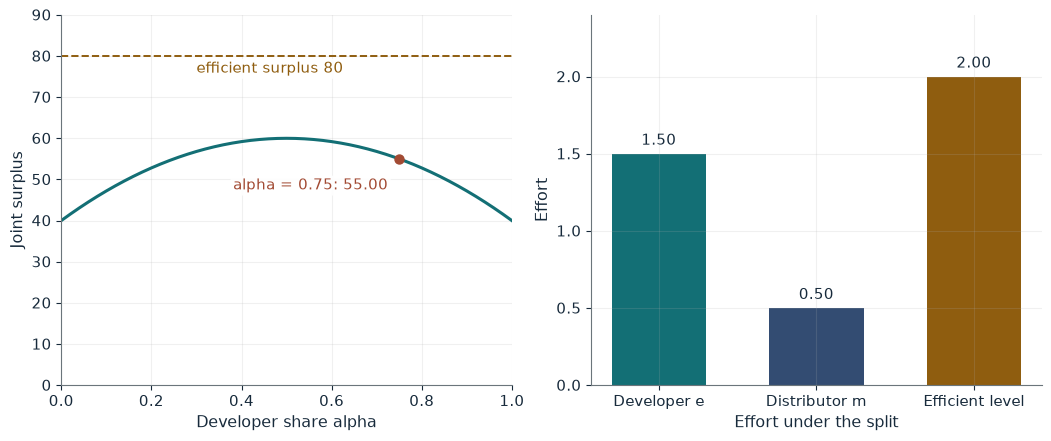

Developer effort e    1.50
Distributor effort m  0.50
Revenue               80.00
Effort cost           25.00
Joint surplus         55.00
Efficient surplus     80.00

Worked steps:
  1. Developer: 0.75 x 40 = 20e, so e = 30.00 / 20 = 1.50
  2. Distributor: 0.25 x 40 = 20m, so m = 10.00 / 20 = 0.50
  3. Revenue = 40 x 1.50 + 40 x 0.50 = 80.00
  4. Cost = 10 x (2.2500 + 0.2500) = 25.00
  5. Surplus = 80.00 - 25.00 = 55.00, 25.00 below the efficient 80.00

With share 0.75 the developer sets e = 1.50 and the distributor m = 0.50. Revenue is 80.00 and effort cost 25.00, so joint surplus is 55.00, 25.00 short of the efficient 80.00. Tilting the share raises one effort and lowers the other by the same amount, so revenue is unchanged, but the convex effort costs rise and joint surplus falls. Hand check: Developer: 0.75 x 40 = 20e, so e = 30.00 / 20 = 1.50; Distributor: 0.25 x 40 = 20m, so m = 10.00 / 20 = 0.50; Revenue = 40 x 1.50 + 40 x 0.50 = 80.00; Cost = 10 x (2.2500 + 0.2500) = 25.00; Sur

In [2]:
show(sharing_picture(alpha=0.75))

Change one input, `alpha`, and hold the others at the book's values:

In [3]:
sweep(sharing_picture, 'alpha', [0.5, 0.6, 0.75, 0.9], {}, ['Developer effort e', 'Distributor effort m', 'Joint surplus'])

alpha | Developer effort e | Distributor effort m | Joint surplus
0.5 | 1.00 | 1.00 | 60.00
0.6 | 1.20 | 0.80 | 59.20
0.75 | 1.50 | 0.50 | 55.00
0.9 | 1.80 | 0.20 | 47.20


Revenue stays at 80 for every share, but cost rises as the split tilts, so surplus falls from 60 at an even split to 55 at 0.75 and 47.20 at 0.90. The efficient 80 needs verifiable effort.

## 2. Limited-liability information rents

High effort costs 12 and raises success probability from 0.30 to 0.70; success is worth 100. With a zero failure wage,

$$(0.70-0.30)w_H\geq12$$

so $w_H=30$. With a failure charge, $0.70(21)+0.30(-9)=12$.

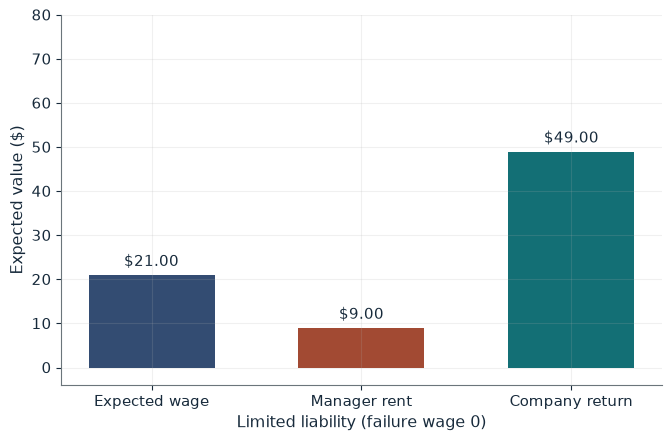

Success wage w_H  $30.00
Failure wage w_L  $0.00
Expected wage     $21.00
Manager rent      $9.00
Company return    $49.00

Worked steps:
  1. Spread: 0.40 x (w_H - w_L) = 12, so w_H - w_L = 12 / 0.40 = 30.00
  2. With w_L = 0, w_H = 30.00
  3. Expected wage = 0.70 x 30.00 = 21.00
  4. Rent = 21.00 - 12 = 9.00
  5. Company = 0.70 x 100 - 21.00 = 49.00

High effort needs a pay spread of $30.00. The manager is then indifferent between efforts, and the chapter's convention assigns high effort. Expected wage is $21.00 and the company keeps $49.00. The wage floor forces the whole spread into the success wage, so the manager keeps a rent of $9.00, equal to 12 x 0.30 / 0.40. Hand check: Spread: 0.40 x (w_H - w_L) = 12, so w_H - w_L = 12 / 0.40 = 30.00; With w_L = 0, w_H = 30.00; Expected wage = 0.70 x 30.00 = 21.00; Rent = 21.00 - 12 = 9.00; Company = 0.70 x 100 - 21.00 = 49.00.


In [4]:
show(liability_picture(cost=12, liability='limited'))

Change one input, `cost`, and hold the others at the book's values:

In [5]:
sweep(liability_picture, 'cost', [8, 12, 16], {'liability': 'limited'}, ['Success wage w_H', 'Manager rent', 'Company return'])

cost | Success wage w_H | Manager rent | Company return
8 | $20.00 | $6.00 | $56.00
12 | $30.00 | $9.00 | $49.00
16 | $40.00 | $12.00 | $42.00


The rent is 0.75 times the effort cost: 6, 9 and 12. With `liability='unlimited'` the rent disappears and the company keeps 58 in the book case.

## 3. Moral hazard: a deductible restores care

Care costs 80 and cuts the chance of a 2,000 accident from 0.10 to 0.02. With deductible $D$ the private saving from care is $0.08D$; the book's 1,500 deductible gives

$$(0.10-0.02)(\$1{,}500)=\$120$$

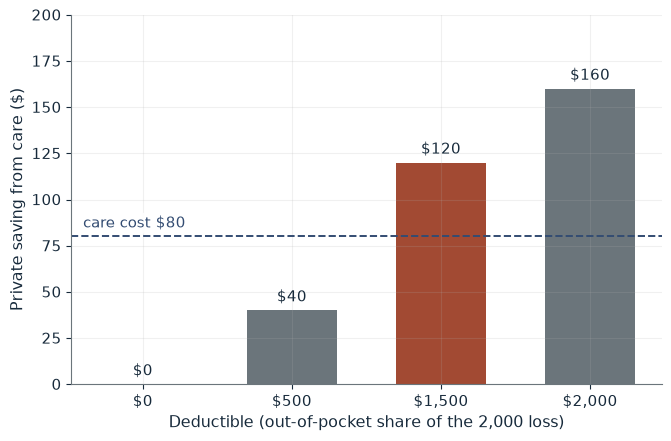

Private saving from care      $120.00
Care taken                    yes
Expected resource cost        $120.00
Smallest deductible for care  above $1,000

Worked steps:
  1. Saving = (0.10 - 0.02) x 1,500 = 120.00
  2. Compare with care cost 80: 120.00 > 80, so care is taken
  3. Resource cost = 80 + 0.02 x 2,000 = 120.00
  4. Care needs D > 80 / 0.08 = 1,000

With a $1,500 deductible, care cuts the driver's expected out-of-pocket loss by $120.00, more than the $80 care cost, so the driver takes care and the expected resource cost is $80 + $40 = $120. Any deductible above $1,000 restores care. Hand check: Saving = (0.10 - 0.02) x 1,500 = 120.00; Compare with care cost 80: 120.00 > 80, so care is taken; Resource cost = 80 + 0.02 x 2,000 = 120.00; Care needs D > 80 / 0.08 = 1,000.


In [6]:
show(deductible_picture(deductible=1500))

Change one input, `deductible`, and hold the others at the book's values:

In [7]:
sweep(deductible_picture, 'deductible', [0, 500, 1500, 2000], {}, ['Private saving from care', 'Care taken', 'Expected resource cost'])

deductible | Private saving from care | Care taken | Expected resource cost
0 | $0.00 | no | $200.00
500 | $40.00 | no | $200.00
1500 | $120.00 | yes | $120.00
2000 | $160.00 | yes | $120.00


Care returns once $0.08D$ exceeds 80, that is above a 1,000 deductible; exactly 1,000 is a tie and is left out. Resource cost falls from 200 to 120 when care is taken.

## 4. Principal-agent problem: base plus bonus

The outside option is \$20,000; high effort costs \$6,000 and raises the chance of a \$100,000 sale from 0.20 to 0.50. With a \$15,000 base and a \$22,000 bonus,

$$\$15{,}000+0.20(\$22{,}000)=\$19{,}400$$

under low effort, and high effort nets \$20,000.

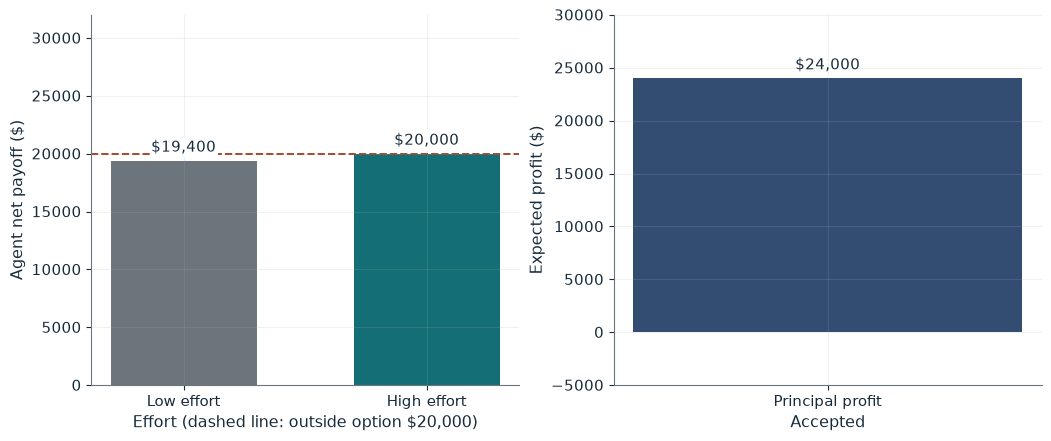

Low effort pay     $19,400
High effort pay    $26,000
High effort net    $20,000
Effort chosen      High
Contract accepted  yes
Principal profit   $24,000

Worked steps:
  1. Low effort: 15,000 + 0.20 x 22,000 = 19,400
  2. High effort: 15,000 + 0.50 x 22,000 - 6,000 = 20,000
  3. Agent picks high effort and nets 20,000 against the 20,000 outside option
  4. Profit = 0.50 x 100,000 - 26,000 = 24,000

Low effort nets $19,400; high effort pays $26,000 and nets $20,000 after the $6,000 effort cost. The contract induces high effort and the representative accepts, leaving the principal $24,000. Hand check: Low effort: 15,000 + 0.20 x 22,000 = 19,400; High effort: 15,000 + 0.50 x 22,000 - 6,000 = 20,000; Agent picks high effort and nets 20,000 against the 20,000 outside option; Profit = 0.50 x 100,000 - 26,000 = 24,000.


In [8]:
show(bonus_picture(bonus=22000, base=15000))

Change one input, `bonus`, and hold the others at the book's values:

In [9]:
sweep(bonus_picture, 'bonus', [0, 15000, 20000, 22000], {'base': 15000}, ['Low effort pay', 'High effort net', 'Contract accepted', 'Principal profit'])

bonus | Low effort pay | High effort net | Contract accepted | Principal profit
0 | $15,000 | $9,000 | no | $0
15000 | $18,000 | $16,500 | no | $0
20000 | $19,000 | $19,000 | no | $0
22000 | $19,400 | $20,000 | yes | $24,000


With a 15,000 base only the 22,000 bonus both induces high effort and clears the outside option; the principal then earns 0.50 x 100,000 - 26,000 = \$24,000.

## Your numbers

Replace the inputs below with your own and run the cell. Every function above accepts any value in the range its section describes.

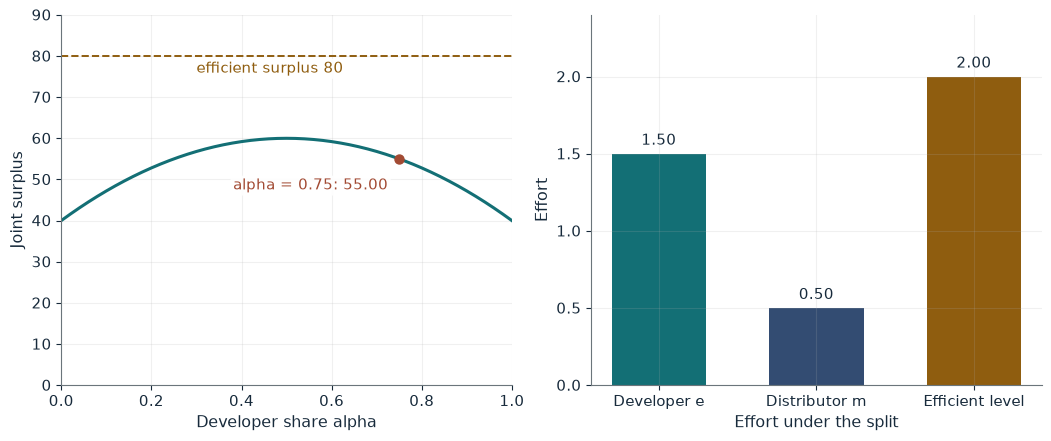

Developer effort e    1.50
Distributor effort m  0.50
Revenue               80.00
Effort cost           25.00
Joint surplus         55.00
Efficient surplus     80.00

Worked steps:
  1. Developer: 0.75 x 40 = 20e, so e = 30.00 / 20 = 1.50
  2. Distributor: 0.25 x 40 = 20m, so m = 10.00 / 20 = 0.50
  3. Revenue = 40 x 1.50 + 40 x 0.50 = 80.00
  4. Cost = 10 x (2.2500 + 0.2500) = 25.00
  5. Surplus = 80.00 - 25.00 = 55.00, 25.00 below the efficient 80.00

With share 0.75 the developer sets e = 1.50 and the distributor m = 0.50. Revenue is 80.00 and effort cost 25.00, so joint surplus is 55.00, 25.00 short of the efficient 80.00. Tilting the share raises one effort and lowers the other by the same amount, so revenue is unchanged, but the convex effort costs rise and joint surplus falls. Hand check: Developer: 0.75 x 40 = 20e, so e = 30.00 / 20 = 1.50; Distributor: 0.25 x 40 = 20m, so m = 10.00 / 20 = 0.50; Revenue = 40 x 1.50 + 40 x 0.50 = 80.00; Cost = 10 x (2.2500 + 0.2500) = 25.00; Sur

In [10]:
show(sharing_picture(alpha=0.75))

## Practice

**1.** In the revenue split, what are e, m and joint surplus at alpha = 0.60?

<details><summary>Answer</summary>

e = 0.60 x 40 / 20 = 1.2 and m = 0.40 x 40 / 20 = 0.8; cost 10 x (1.44 + 0.64) = 20.8 and surplus 80 - 20.8 = 59.2.

</details>

**2.** With effort cost 8 under limited liability, what are the success wage, the rent and the company return?

<details><summary>Answer</summary>

w_H = 8 / 0.40 = 20, expected wage 0.70 x 20 = 14, rent 14 - 8 = 6, company 70 - 14 = 56.

</details>

**3.** With a 20,000 base and a 15,000 bonus, which effort is chosen and what does the principal earn?

<details><summary>Answer</summary>

Low effort pays 20,000 + 3,000 = 23,000; high effort nets 20,000 + 7,500 - 6,000 = 21,500, so low effort. The principal earns 0.20 x 100,000 - 23,000 = -3,000.

</details>